# 03 - Modelamiento 01: Regresión Lineal (modelo base)

**Problema:** predecir `Profit` (variable continua), por lo tanto es un problema de **regresión**.

**Plan:** entrenar una Regresión Lineal con `train`, evaluarla con `test` y calcular MAE, RMSE y R². Este modelo sirve como punto de comparación para el Random Forest del siguiente cuadernillo.

In [1]:
import sys
sys.path.append("../..")

import pandas as pd
import matplotlib.pyplot as plt

from src.carga_datos import cargar_csv
from src.transformacion import separar_x_y
from src.entrenamiento import entrenar_regresion_lineal
from src.evaluacion import calcular_metricas, graficar_real_vs_predicho, graficar_residuos

## 1. Carga de train y test
Se usan los archivos generados en la limpieza. El conjunto de prueba solo se usa al evaluar.

In [2]:
train = cargar_csv("../../data/train/train.csv")
test = cargar_csv("../../data/test/test.csv")

X_train, y_train = separar_x_y(train, "Profit")
X_test, y_test = separar_x_y(test, "Profit")

print("X_train:", X_train.shape, "| X_test:", X_test.shape)

X_train: (7959, 39) | X_test: (2035, 39)


## 2. Referencia mínima
Antes de entrenar, calculo qué error se tendría si siempre se predijera el Profit promedio de train. Cualquier modelo útil debería mejorar esto.

In [3]:
prediccion_promedio = pd.Series(y_train.mean(), index=y_test.index)
metricas_referencia = calcular_metricas(y_test, prediccion_promedio)
print({nombre: round(valor, 2) for nombre, valor in metricas_referencia.items()})

{'MAE': 66.33, 'RMSE': 232.27, 'R2': -0.0}


## 3. Entrenamiento con train

In [4]:
modelo_lineal = entrenar_regresion_lineal(X_train, y_train)
print("Modelo entrenado con", X_train.shape[1], "variables")

Modelo entrenado con 39 variables


## 4. Evaluación con test

In [5]:
y_predicho = modelo_lineal.predict(X_test)
metricas_lineal = calcular_metricas(y_test, y_predicho)

for nombre, valor in metricas_lineal.items():
    print(f"{nombre}: {valor:.3f}")

MAE: 61.924
RMSE: 171.369
R2: 0.455


## 5. Gráficos

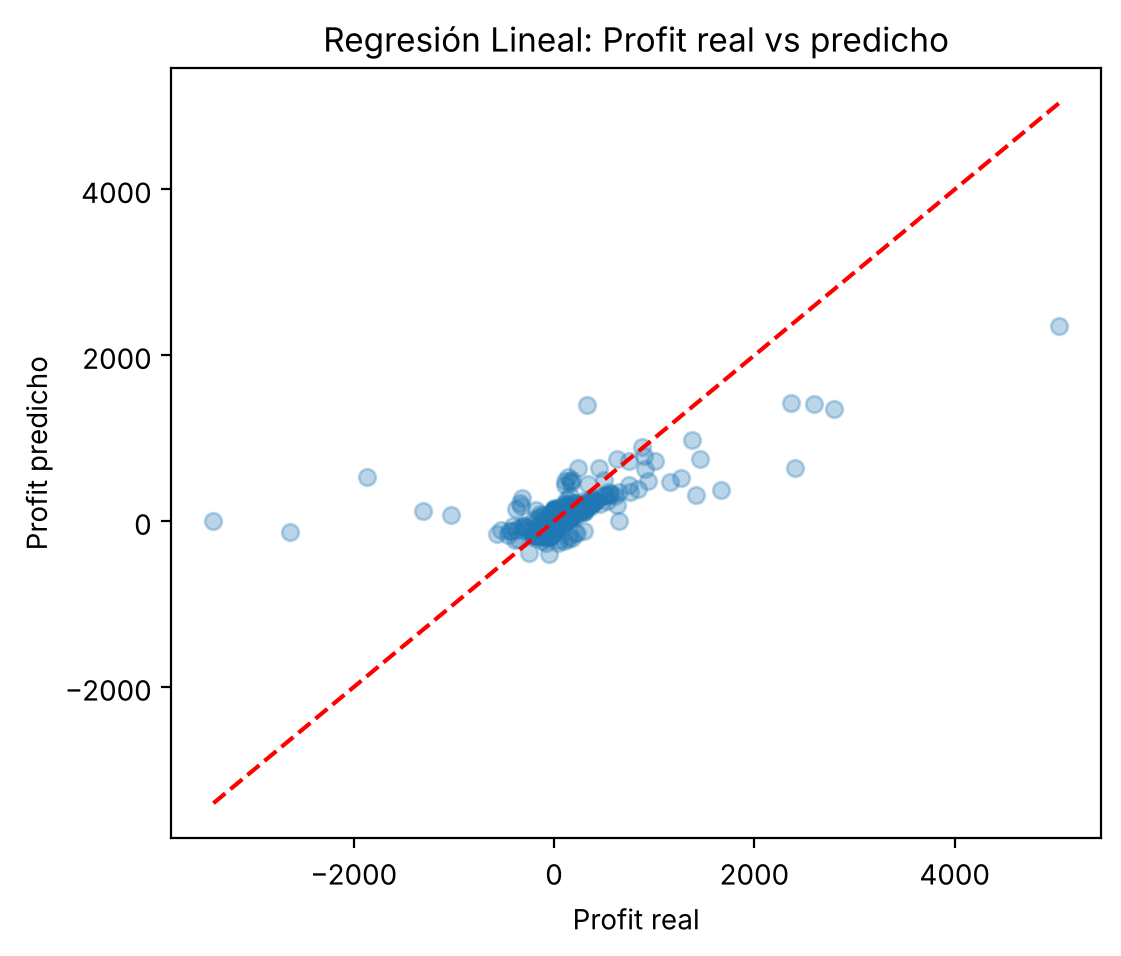

In [6]:
graficar_real_vs_predicho(y_test, y_predicho, "Regresión Lineal: Profit real vs predicho")

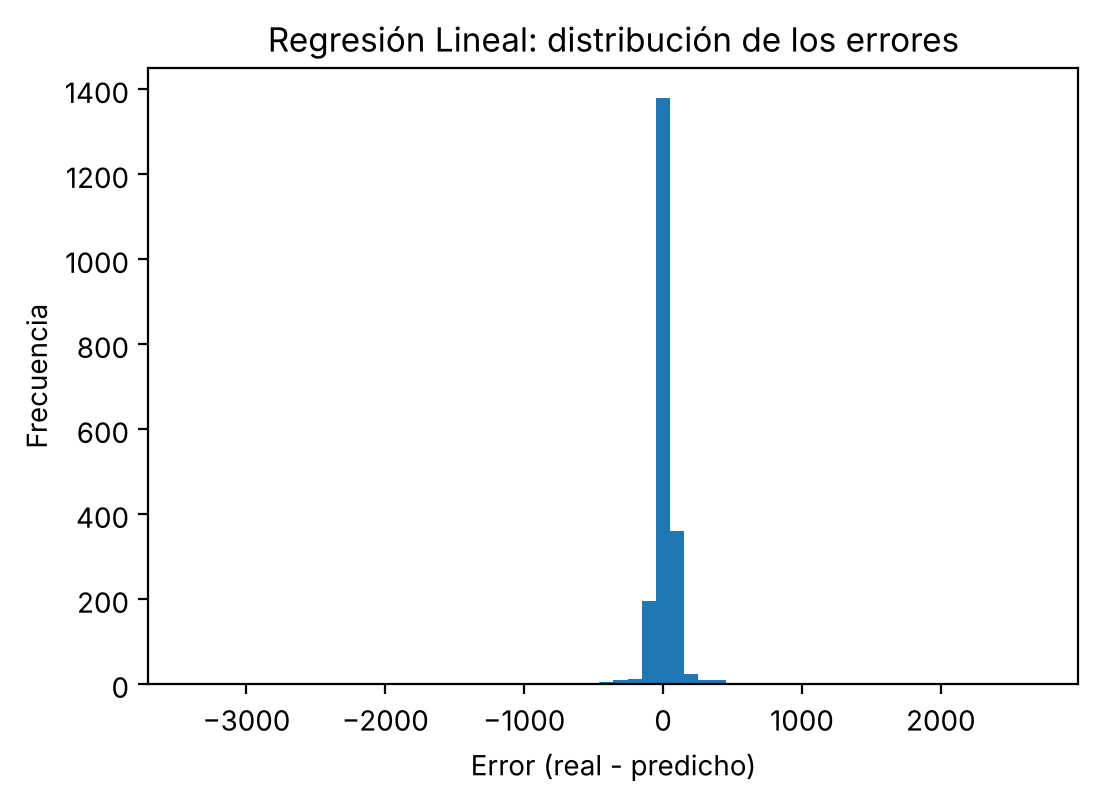

In [7]:
graficar_residuos(y_test, y_predicho, "Regresión Lineal: distribución de los errores")

## 6. Coeficientes más influyentes

In [8]:
coeficientes = pd.Series(modelo_lineal.coef_, index=X_train.columns)
coeficientes.reindex(coeficientes.abs().sort_values(ascending=False).index).head(10).round(2)

Sub-Category_Copiers        399.62
Discount                   -304.72
Sub-Category_Machines      -276.23
Sub-Category_Binders         68.69
Sub-Category_Tables         -65.55
Sub-Category_Supplies       -58.77
Category_Technology          48.27
Sub-Category_Phones         -39.09
Sub-Category_Accessories    -36.02
Category_Furniture          -33.70
dtype: float64

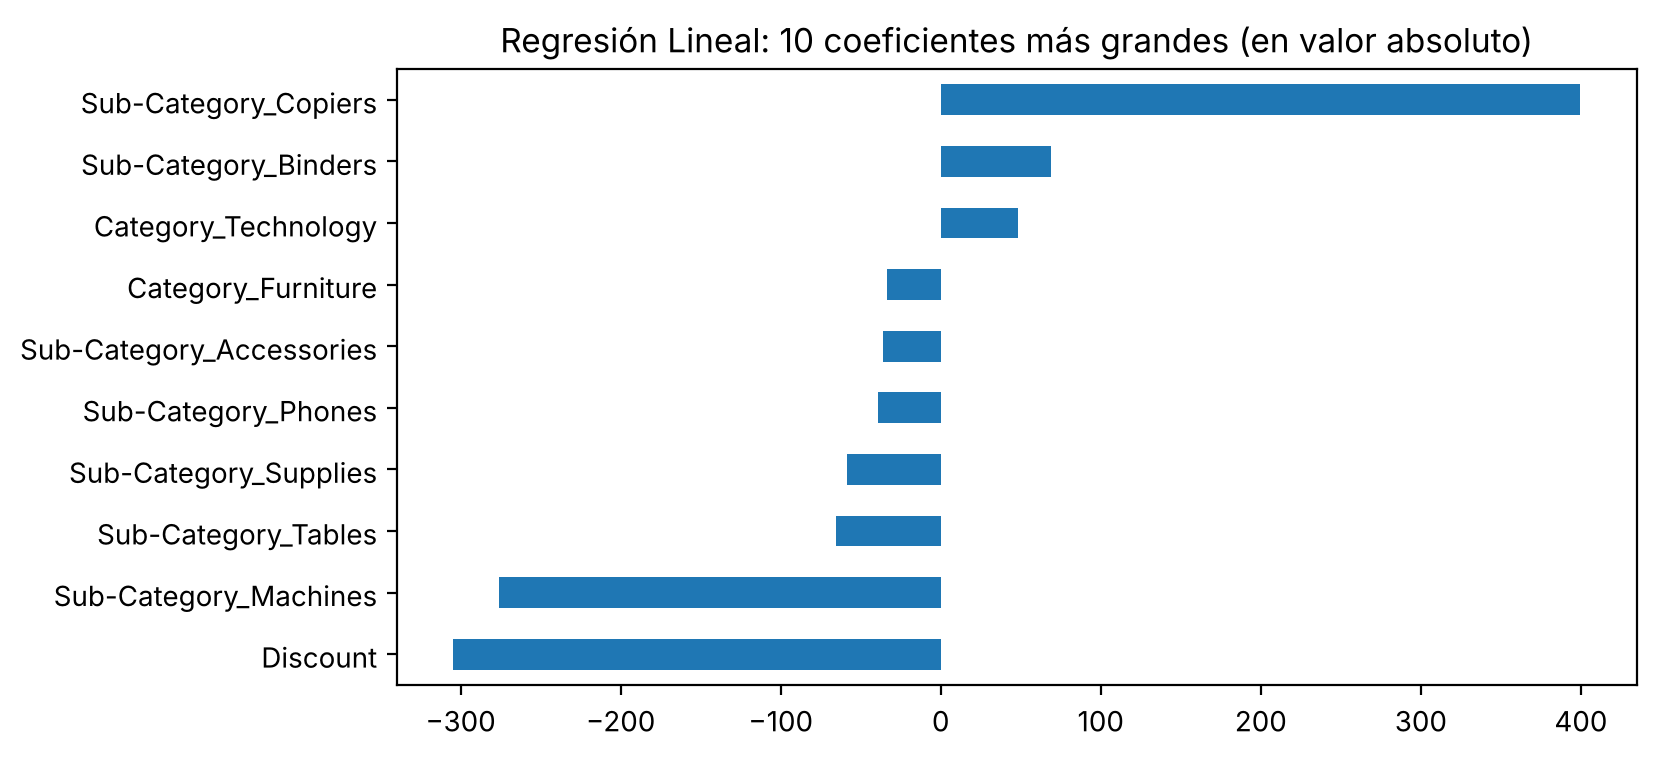

In [9]:
coeficientes.reindex(coeficientes.abs().sort_values(ascending=False).index).head(10).sort_values().plot(kind="barh", figsize=(8, 4))
plt.title("Regresión Lineal: 10 coeficientes más grandes (en valor absoluto)")
plt.show()

## 7. Interpretación y conclusiones

**Resultados en test.** MAE de 61,92, RMSE de 171,37 y R² de 0,455. Como referencia, predecir siempre el promedio da un MAE de 66,33, un RMSE de 232,27 y un R² de 0. El modelo lineal mejora el RMSE y el R², pero el MAE casi no cambia (de 66,33 a 61,92), es decir, en el error típico por registro mejora poco.

**Qué significa.** Con un R² de 0,455, el modelo explica menos de la mitad de la variación del Profit. El gráfico de real contra predicho muestra que los puntos están bastante dispersos alrededor de la línea roja, y que el modelo no logra predecir bien las pérdidas grandes ni las ganancias grandes. El histograma de errores está concentrado cerca de cero pero tiene colas largas, que son los registros extremos que ya habíamos visto en la exploración.

**Coeficientes.** El coeficiente de `Discount` es negativo y grande (-304,72), lo que concuerda con lo que se vio en la exploración: más descuento, menos ganancia. Los coeficientes de las subcategorías hay que interpretarlos con cuidado, porque `Category` y `Sub-Category` se solapan (cada subcategoría pertenece a una sola categoría) y eso hace que los valores se repartan entre ambas variables. Por eso no concluyo, por ejemplo, que `Machines` sea una subcategoría mala solo por tener un coeficiente negativo.

**Ventajas del modelo.** Es rápido, simple y fácil de explicar, y sirve como punto de comparación.

**Limitaciones.** Asume una relación lineal entre cada variable y el Profit. En la exploración se vio que el descuento no se comporta así (el Profit promedio es positivo hasta 20% y se vuelve negativo desde 30%), por lo que un modelo lineal no puede capturar ese cambio. Además es sensible a los valores extremos. Esto motiva probar un Random Forest en el siguiente cuadernillo.